# KNMI forcing — Berkhout (station 249)

Hourly precipitation and Makkink evaporation from 2020 up to now, written to
`input_output/knmi_berkhout.csv` (`Time,precipitation_mm,makkink_mm`) for the forcing
overlay in the Streamlit review app.

- **Source:** the public KNMI script endpoints (daggegevens.knmi.nl). No API key or quota,
  about a second per year of data, so each run refetches the full period. There is no
  incremental state to keep in sync.
- **Precipitation:** hourly `RH`.
- **Evaporation:** KNMI only publishes Makkink per day (`EV24`). It is spread over that
  day's hours in proportion to hourly global radiation `Q`, so the daily and yearly totals
  equal KNMI's official EV24.
- **Time:** naive UTC, labelled at the end of the hour (the 01:00 row holds 00:00–01:00).

Runs locally: the Databricks cluster has no outbound internet. Commit the CSV afterwards.

In [1]:
import sys
from pathlib import Path

# Make the repo importable wherever Jupyter was started (repo root or local_validation/).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "local_validation").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from local_validation import data_io, knmi

settings = data_io.load_settings()
STATION = int(settings.get("forcing_station", 249))  # 249 = Berkhout
START = "2020-01-01"
OUT = data_io.assert_writable(settings, data_io._path(settings, "forcing_file"))
print(f"station {STATION}, from {START} -> {OUT.relative_to(ROOT)}")

station 249, from 2020-01-01 -> input_output\knmi_berkhout.csv


## Fetch

In [2]:
df = knmi.forcing(STATION, start=START)

expected = pd.date_range(df.index[0], df.index[-1], freq="1h")
missing_hours = expected.difference(df.index)
problems = []
if len(missing_hours):
    problems.append(f"{len(missing_hours)} missing hours, first {missing_hours[0]}")
if df[knmi.COLUMNS].isna().any().any():
    problems.append(f"NaNs: {df[knmi.COLUMNS].isna().sum().to_dict()}")
if (df[knmi.COLUMNS] < 0).any().any():
    problems.append("negative values")

print(f"{len(df):,} hours, {df.index[0]} .. {df.index[-1]}")
print("checks:", "OK" if not problems else "; ".join(problems))

59,736 hours, 2020-01-01 01:00:00 .. 2026-10-25 00:00:00
checks: OK


## Yearly totals

In [3]:
yearly = knmi.yearly_totals(df)
last_year = int(yearly.index.max())
print("year - precipitation - evaporation (mm)")
for year, row in yearly.iterrows():
    partial = f"  (partial, up to {df.index[-1]:%Y-%m-%d})" if year == last_year else ""
    print(f"{year} - {row.precipitation_mm:6.1f} - {row.makkink_mm:6.1f}{partial}")

year - precipitation - evaporation (mm)
2020 -  938.5 -  656.1
2021 -  851.6 -  602.5
2022 -  737.0 -  697.1
2023 - 1127.9 -  648.6
2024 - 1050.2 -  631.4
2025 -  737.8 -  689.1
2026 -  645.4 -  656.8  (partial, up to 2026-10-25)


## Cumulative since 2020

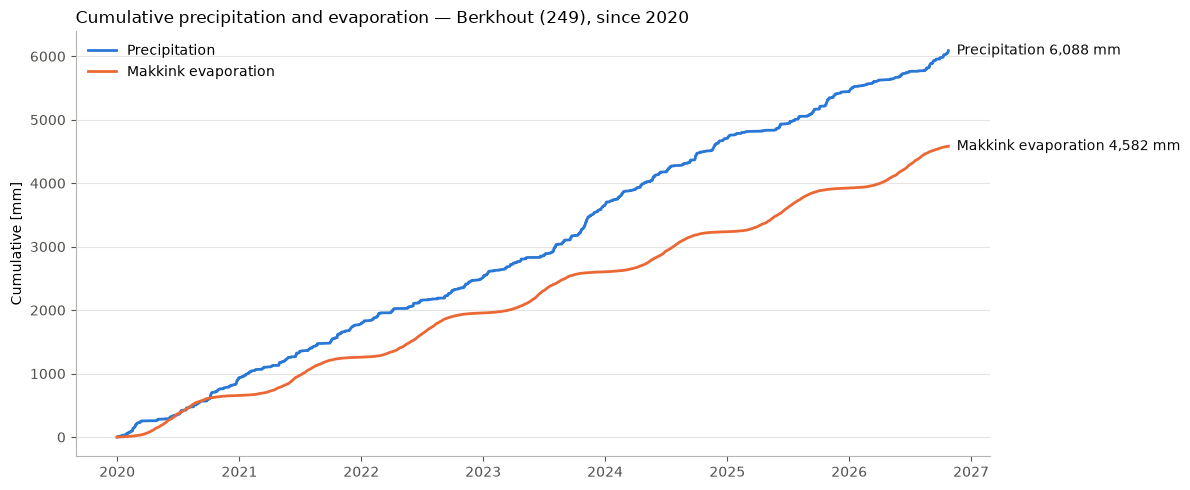

In [4]:
PREC, EVAP = "#2a78d6", "#eb6834"          # categorical slots 1 (blue) and 2 (orange)
YEAR_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6",
               "#e34948"]                  # fixed order, one per year

def style(ax):
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#b5b4ae")
    ax.tick_params(colors="#52514e")

cum = df[knmi.COLUMNS].cumsum()
fig, ax = plt.subplots(figsize=(12, 5))
for col, colour, label in [("precipitation_mm", PREC, "Precipitation"),
                           ("makkink_mm", EVAP, "Makkink evaporation")]:
    ax.plot(cum.index, cum[col], color=colour, linewidth=2, label=label)
    ax.annotate(f"{label} {cum[col].iloc[-1]:,.0f} mm", (cum.index[-1], cum[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color="#0b0b0b")
ax.set_title(f"Cumulative precipitation and evaporation — Berkhout ({STATION}), since {START[:4]}",
             loc="left")
ax.set_ylabel("Cumulative [mm]")
ax.legend(frameon=False, loc="upper left")
style(ax)
fig.tight_layout()
plt.show()

## Year on year

Cumulative total within each calendar year, against the day of the year. One colour per year,
the same in both panels. The current year stops at the latest data.

C:\Users\jvanruitenbeek\AppData\Local\Temp\181\ipykernel_53924\2253083713.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  ax.annotate(text, (x, y), xytext=(x + pd.Timedelta(days=4), y_text), va="center",
C:\Users\jvanruitenbeek\AppData\Local\Temp\181\ipykernel_53924\2253083713.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  ax.annotate(text, (x, y), xytext=(x + pd.Timedelta(days=4), y_text), va="center",


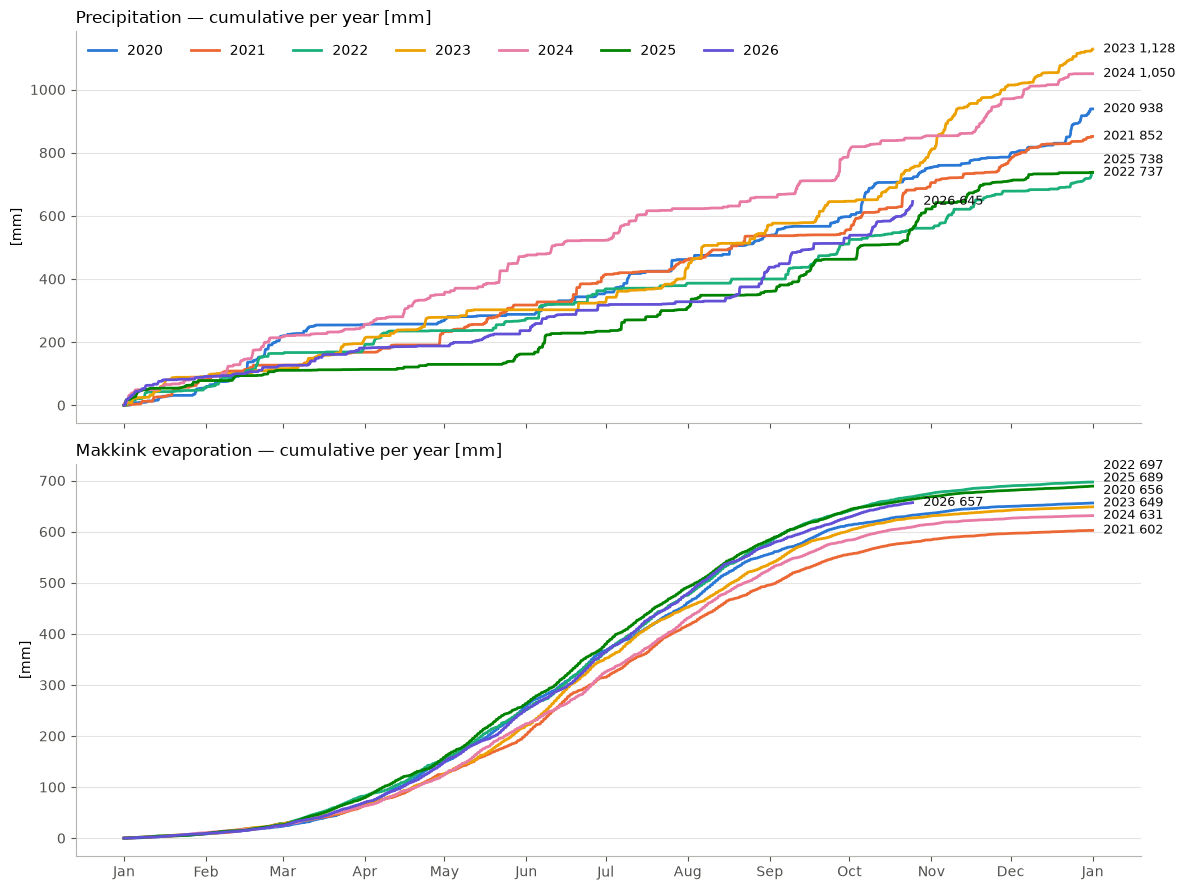

In [5]:
start_of_hour = knmi.hour_start(df)
per_year = df[knmi.COLUMNS].groupby(start_of_hour.year).cumsum()
# Plot every year on a common (leap) calendar so the x-axis reads as months.
common_time = pd.to_datetime({"year": 2020, "month": start_of_hour.month, "day": start_of_hour.day,
                              "hour": start_of_hour.hour})

def label_ends(ax, ends, min_gap):
    # Direct labels at line ends, nudged apart vertically when the totals are close.
    placed = []
    for x, y, text in sorted(ends, key=lambda e: e[1]):
        y_text = max(y, placed[-1] + min_gap) if placed else y
        placed.append(y_text)
        ax.annotate(text, (x, y), xytext=(x + pd.Timedelta(days=4), y_text), va="center",
                    fontsize=9, color="#0b0b0b", annotation_clip=False)

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for ax, col, label in [(axes[0], "precipitation_mm", "Precipitation"),
                       (axes[1], "makkink_mm", "Makkink evaporation")]:
    ends = []
    for i, year in enumerate(sorted(start_of_hour.year.unique())):
        mask = start_of_hour.year == year
        x, y = common_time[mask], per_year.loc[mask, col]
        ax.plot(x, y, color=YEAR_COLORS[i % len(YEAR_COLORS)], linewidth=2, label=str(year))
        ends.append((x.iloc[-1], y.iloc[-1], f"{year} {y.iloc[-1]:,.0f}"))
    full = [e for e in ends if (e[0].month, e[0].day) == (12, 31)]  # complete years
    label_ends(ax, full, min_gap=0.035 * per_year[col].max())
    label_ends(ax, [e for e in ends if e not in full], min_gap=0)
    ax.set_title(f"{label} — cumulative per year [mm]", loc="left")
    ax.set_ylabel("[mm]")
    style(ax)
axes[0].legend(frameon=False, ncol=7, loc="upper left")
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.tight_layout()
plt.show()

## Write the forcing file

Only written when the checks above passed. The review app picks it up as **KNMI forcing** in
the Review page sidebar.

In [6]:
if problems:
    raise RuntimeError("not writing the forcing file: " + "; ".join(problems))
df.round(4).to_csv(OUT, date_format="%Y-%m-%d %H:%M:%S")
check = pd.read_csv(OUT, index_col=0, parse_dates=True)
print(f"wrote {OUT.relative_to(ROOT)}: {len(check):,} rows, columns {list(check.columns)}")

wrote input_output\knmi_berkhout.csv: 59,736 rows, columns ['precipitation_mm', 'makkink_mm']
